# Segmentación pulmonar

Entrenamiento y evaluación de las redes de segmentación pulmonar del proyecto.

El objetivo del proyecto no es obtener el mejor segmentador, sino **medir si la técnica de segmentación cambia las características radiómicas y el desempeño de los modelos de detección de tuberculosis**. La segmentación es un paso intermedio: todas las técnicas que pasen el control de calidad continúan a la extracción con pyradiomics. De ahí dos exigencias:

- Todas las técnicas se entrenan y evalúan **en igualdad de condiciones**, para que las diferencias posteriores se atribuyan a la técnica y no al protocolo.
- Agregar una técnica nueva no debe obligar a rehacer las etapas siguientes.

**Estado de este notebook:** U-Net y Attention U-Net entrenadas y comparadas. MedSAM se agregará después.

| Sección | Contenido |
|---|---|
| 1 | Configuración común a todas las corridas |
| 2 | Datos de entrenamiento (Montgomery + Shenzhen) |
| 3 | Arquitecturas |
| 4 | Entrenamiento |
| 5 | Curvas de aprendizaje |
| 6 | Calidad de la segmentación en el conjunto de prueba |
| 7+ | Siguientes pasos (pendientes) |

## 1. Configuración común

Los parámetros viven en `src/tbseg/segmentation/train.py` y se importan aquí, para que el notebook muestre **los valores que realmente se usaron** y no una copia que puede quedar desactualizada.

Entre corridas solo cambian dos cosas: la **arquitectura** y la **semilla**. Todo lo demás (datos, partición, aumentos, pérdida, optimizador, épocas) es idéntico.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tbseg.config import IMAGE_SIZE, RESULTS_DIR, SEGTRAIN_CSV, SEGTRAIN_DIR
from tbseg.segmentation import train as T

SEG_RESULTS_DIR = RESULTS_DIR / "segmentation"
SEEDS = [42, 43, 44]

config = pd.Series({
    "Resolución": f"{IMAGE_SIZE}×{IMAGE_SIZE}",
    "Tamaño de lote": T.BATCH_SIZE,
    "Optimizador": f"Adam (lr={T.LEARNING_RATE})",
    "Pérdida": "BCE + Dice",
    "Épocas máximas": T.MAX_EPOCHS,
    "Detención temprana": f"{T.PATIENCE} épocas sin mejorar el Dice de validación",
    "Canales por nivel": str(T.CHANNELS),
    "Umbral de binarización": T.THRESHOLD,
    "Semillas": ", ".join(map(str, SEEDS)),
}).to_frame("valor")
config.index.name = "parámetro"
display(config)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
C_TRUE, C_PRED = "#2a78d6", "#eb6834"   # azul: máscara real | naranja: predicción
ARCH_NAMES = {"unet": "U-Net", "attention_unet": "Attention U-Net"}
ARCH_COLORS = {"unet": "#2a78d6", "attention_unet": "#1baf7a"}

/home/julian/proyects/tuberculosis-lung-segmentation/.venv/lib/python3.10/site-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


,valor
parámetro,
Resolución,512×512
Tamaño de lote,8
Optimizador,Adam (lr=0.001)
Pérdida,BCE + Dice
Épocas máximas,60
Detención temprana,10 épocas sin mejorar el Dice de validación
Canales por nivel,"(16, 32, 64, 128, 256)"
Umbral de binarización,0.5
Semillas,"42, 43, 44"


**Aumento de datos** (solo en entrenamiento, definido en `train.augment`): rotación ±10°, escala 0.9–1.1, traslación hasta 5 % y cambios de brillo y contraste (±20 % y ±0.1). Las transformaciones geométricas se aplican **igual a la imagen y a su máscara**; las de intensidad, solo a la imagen.

Cada rango imita una variación que ocurre entre radiografías reales: la inclinación del paciente frente al detector (rotación), su distancia y contextura (escala), el encuadre del técnico (traslación) y la exposición del equipo (brillo y contraste). Son rangos pequeños a propósito: una radiografía de tórax es una proyección estandarizada, así que deformarla más generaría imágenes que no existen en la práctica. **No se usa volteo horizontal** porque pondría el corazón a la derecha.

La práctica viene del artículo original de U-Net, que entrenaba con pocas imágenes y usaba desplazamiento, rotación y deformaciones elásticas, y es estándar en segmentación pulmonar en radiografía: rotación, traslación y escala aparecen de forma sistemática en los trabajos sobre Montgomery y Shenzhen.

## 2. Datos de entrenamiento

TBX11K no tiene máscaras de pulmón, así que las redes se entrenan con **Montgomery + Shenzhen**: 704 radiografías con máscaras trazadas manualmente bajo supervisión de radiólogos. `python -m tbseg.segmentation.prepare` ya las dejó a 512×512 y escribió la partición en `data/metadata/segtrain_split.csv`.

- **train (70 %)**: con lo que la red aprende.
- **val (15 %)**: vigila el entrenamiento, decide la detención temprana y selecciona la mejor época.
- **test (15 %)**: se usa **una sola vez**, al final, para reportar el desempeño.

La partición se hace **por paciente**: dos pacientes de Montgomery tienen varias radiografías (controles en el tiempo) y todas sus imágenes quedan en la misma partición, para que la red no se evalúe con un paciente que ya vio. Además está estratificada por origen (Montgomery/Shenzhen) y diagnóstico (sano/TB), y es **la misma para todas las corridas**.

704 imágenes de 701 pacientes


split            test  train  val  total
source     tb                           
montgomery TB       9     41    8     58
           sano    12     56   12     80
shenzhen   TB      43    201   43    287
           sano    42    195   42    279
total             106    493  105    704

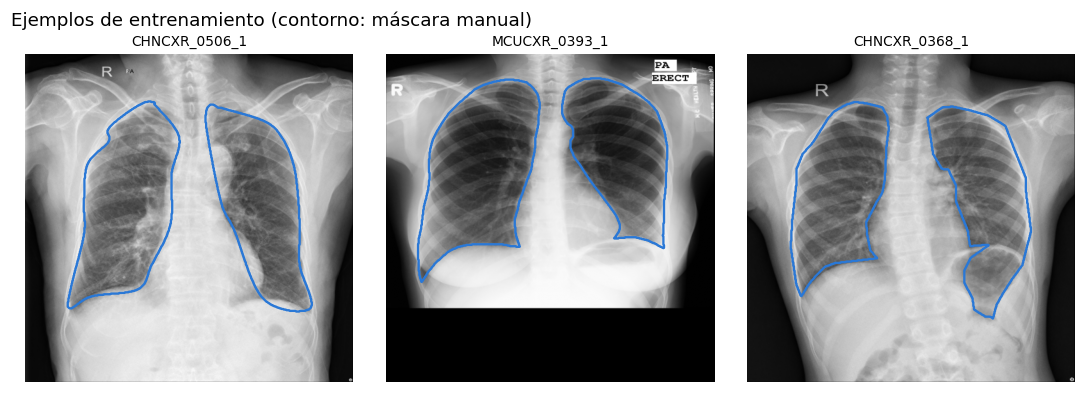

In [2]:
split = pd.read_csv(SEGTRAIN_CSV)
print(f"{len(split)} imágenes de {split['patient_id'].nunique()} pacientes")
display(pd.crosstab([split["source"], split["tb"].map({0: "sano", 1: "TB"})], split["split"],
                    margins=True, margins_name="total"))

ids = split[split["split"] == "train"].sample(3, random_state=0)["image_id"]
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
for ax, image_id in zip(axes, ids):
    img, mask = T.load_pair(image_id)
    ax.imshow(img, cmap="gray"); ax.contour(mask, levels=[0.5], colors=C_TRUE, linewidths=1.5)
    ax.set_title(image_id, fontsize=9); ax.axis("off")
fig.suptitle("Ejemplos de entrenamiento (contorno: máscara manual)", x=0.01, ha="left")
fig.tight_layout()
plt.show()

## 3. Arquitecturas

Se usan las implementaciones de **MONAI**, una librería especializada en imagen médica, con los mismos argumentos para todas las arquitecturas.

- **U-Net** (Ronneberger et al., 2015): un codificador que reduce la resolución y gana contexto, un decodificador que la recupera, y **conexiones de salto** que devuelven el detalle espacial perdido. Es el estándar en segmentación médica y funciona bien con pocos datos.
- **Attention U-Net** (Oktay et al., 2018): la misma estructura, pero agrega **compuertas de atención** en las conexiones de salto, que ponderan cada región según su relevancia antes de combinarla. La idea es que la red atenúe el fondo (hombros, abdomen) y se concentre en el pulmón.

Una explicación detallada de U-Net, pieza por pieza, está en [`tutorial_unet.ipynb`](tutorial_unet.ipynb).

In [3]:
display(pd.DataFrame([
    {"arquitectura": arch, "parámetros": f"{sum(p.numel() for p in T.build_model(arch).parameters()):,}"}
    for arch in T.ARCHITECTURES
]))

,arquitectura,parámetros
0,unet,"659,993"
1,attention_unet,"1,987,417"


## 4. Entrenamiento

El entrenamiento **no se ejecuta dentro del notebook**: son corridas largas que deben poder lanzarse, interrumpirse y repetirse sin depender del estado del kernel. La rutina vive en `src/tbseg/segmentation/train.py` y se ejecuta desde la terminal.

### Qué hace cada corrida

1. **Carga los datos** (`build_loaders`): las 704 imágenes ya preparadas, repartidas en train/val/test según `segtrain_split.csv`. Solo el conjunto de entrenamiento baraja el orden y aplica aumentos.
2. **Crea la red** (`build_model`) y la mueve a la GPU.
3. **Repite por época**: recorre el entrenamiento ajustando pesos y luego evalúa en validación sin ajustarlos.
   - **Pérdida**: `BCE + Dice`. BCE mide el acierto píxel a píxel; Dice mide la superposición entre la máscara predicha y la real.
   - **Optimizador**: Adam, tasa de aprendizaje 0.001.
   - Si el Dice de validación mejora, se guarda una copia de los pesos.
4. **Se detiene** tras 10 épocas sin mejorar el Dice de validación (tope de 60).
5. **Evalúa en prueba una sola vez**, con los pesos de la mejor época.

Prueba rápida antes de una corrida larga (2 épocas con 24 imágenes, no guarda nada):

```bash
python -m tbseg.segmentation.train --arch unet --smoke
```

Las corridas de este notebook:

```bash
for seed in 42 43 44; do python -m tbseg.segmentation.train --arch unet --seed $seed; done
for seed in 42 43 44; do python -m tbseg.segmentation.train --arch attention_unet --seed $seed; done
```

**Por qué tres semillas.** El entrenamiento tiene componentes aleatorios: inicialización de pesos, orden de los lotes y aumentos. Con una sola corrida no se puede saber si una diferencia entre arquitecturas es real o producto del azar. Tres semillas permiten reportar media ± desviación.

### Qué se guarda

| Archivo | Contenido |
|---|---|
| `models/<arch>_seed<n>.pt` | Pesos de la mejor época (no se versiona) |
| `results/segmentation/history.csv` | Pérdida y Dice de cada época, de todas las corridas |
| `results/segmentation/test_per_image.csv` | Dice e IoU de cada imagen de prueba |
| `results/segmentation/test_metrics.csv` | Una fila resumen por corrida |

## 5. Curvas de aprendizaje

Cada corrida dibuja dos líneas:
- **Entrenamiento**: qué tan bien le va con las imágenes que usa para aprender.
- **Validación**: qué tan bien le va con imágenes que nunca usó para ajustar pesos.

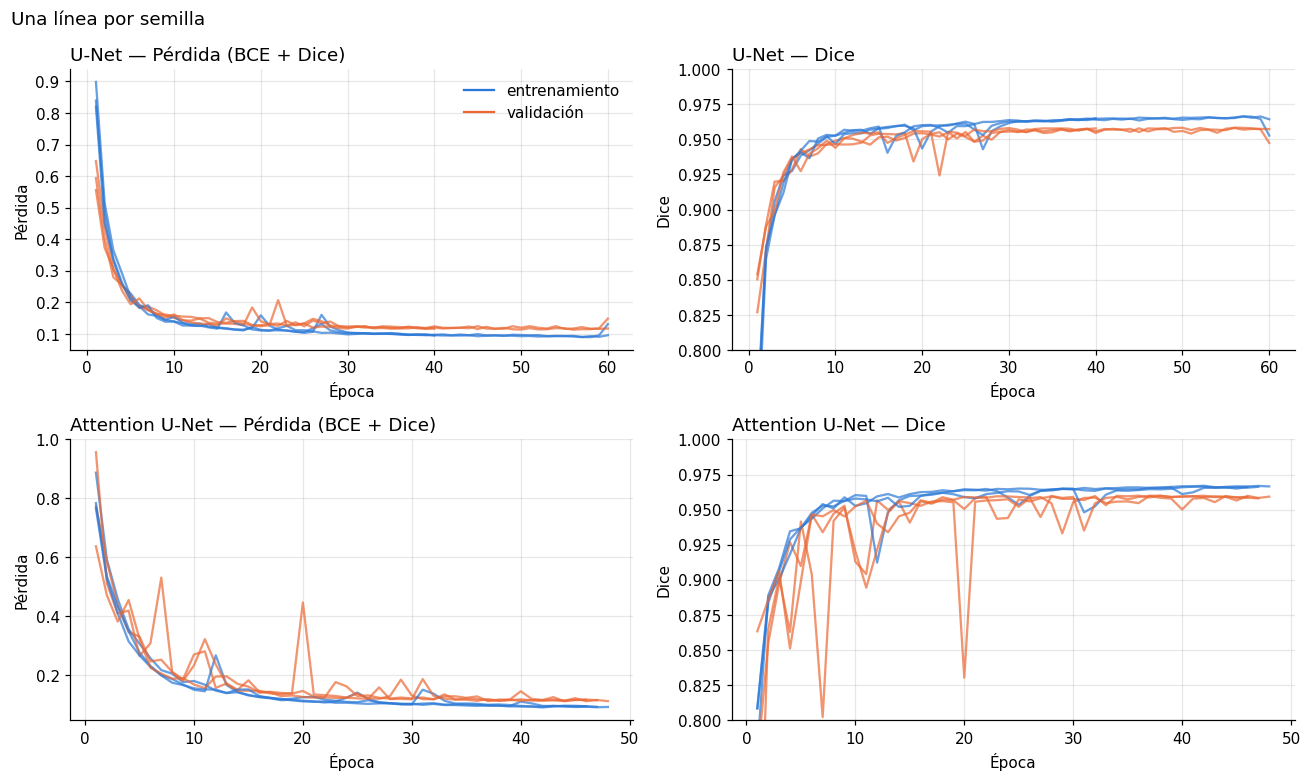

epocas  mejor_val_dice  minutos
arch           seed                                 
attention_unet 42        46           0.960   20.277
               43        47           0.960   20.098
               44        48           0.960   20.485
unet           42        60           0.958    4.679
               43        60           0.958    4.671
               44        40           0.958    3.054

In [4]:
histories = pd.read_csv(SEG_RESULTS_DIR / "history.csv")
archs = [a for a in ARCH_NAMES if a in set(histories["arch"])]

fig, axes = plt.subplots(len(archs), 2, figsize=(12, 3.6 * len(archs)), squeeze=False)
for row, arch in zip(axes, archs):
    for ax, metric, title in [(row[0], "loss", "Pérdida (BCE + Dice)"), (row[1], "dice", "Dice")]:
        for seed, run in histories[histories["arch"] == arch].groupby("seed"):
            ax.plot(run["epoch"], run[f"train_{metric}"], color=C_TRUE, lw=1.5, alpha=0.7)
            ax.plot(run["epoch"], run[f"val_{metric}"], color=C_PRED, lw=1.5, alpha=0.7)
        ax.set_title(f"{ARCH_NAMES[arch]} — {title}", loc="left"); ax.set_xlabel("Época"); ax.grid(alpha=0.3)
    row[0].set_ylabel("Pérdida"); row[1].set_ylabel("Dice"); row[1].set_ylim(0.8, 1.0)
axes[0, 0].plot([], [], color=C_TRUE, label="entrenamiento"); axes[0, 0].plot([], [], color=C_PRED, label="validación")
axes[0, 0].legend(frameon=False)
fig.suptitle("Una línea por semilla", x=0.01, ha="left")
fig.tight_layout()
plt.show()

display(histories.groupby(["arch", "seed"]).agg(
    epocas=("epoch", "max"), mejor_val_dice=("val_dice", "max"), minutos=("minutes", "max")).round(3))

## 6. Calidad de la segmentación (conjunto de prueba)

El conjunto de prueba no participó en ninguna decisión: ni en el entrenamiento, ni en la detención temprana, ni en la selección de la mejor época. Por eso su Dice es una estimación honesta del desempeño sobre radiografías nuevas **del mismo tipo** (Montgomery y Shenzhen).

Dos métricas de superposición entre la máscara predicha y la manual:
- **Dice** = 2·|intersección| / (|predicha| + |real|)
- **IoU** = |intersección| / |unión|, equivalente pero más estricta.

In [5]:
metrics = pd.read_csv(SEG_RESULTS_DIR / "test_metrics.csv")
display(metrics)

summary = metrics.groupby("arch").agg(
    corridas=("seed", "count"),
    dice_medio=("test_dice", "mean"), dice_desv=("test_dice", "std"),
    iou_medio=("test_iou", "mean"), peor_imagen=("test_dice_min", "min")).round(4)
display(summary)

,arch,seed,best_epoch,epochs_run,val_dice,test_dice,test_dice_std,test_dice_min,test_iou,minutes
0,attention_unet,42,36,46,0.9599,0.9645,0.0220,0.8904,0.9323,20.3
1,attention_unet,43,37,47,0.9598,0.9641,0.0212,0.9031,0.9314,20.1
2,attention_unet,44,38,48,0.9600,0.9651,0.0213,0.8957,0.9334,20.5
3,unet,42,56,60,0.9584,0.9631,0.0215,0.8956,0.9296,4.7
4,unet,43,56,60,0.9581,0.9635,0.0217,0.8932,0.9304,4.7
5,unet,44,30,40,0.9580,0.9626,0.0217,0.8911,0.9286,3.1


,corridas,dice_medio,dice_desv,iou_medio,peor_imagen
arch,,,,,
attention_unet,3,0.9646,0.0005,0.9324,0.8904
unet,3,0.9631,0.0005,0.9295,0.8911


La desviación entre semillas indica cuánto varía el resultado solo por el azar del entrenamiento. Es la referencia con la que habrá que comparar la diferencia frente a Attention U-Net: si la diferencia entre arquitecturas es menor que esta variación, no es concluyente.

count   mean    std    min
arch           source                                
attention_unet montgomery   63.0  0.977  0.017  0.903
               shenzhen    255.0  0.961  0.021  0.890
unet           montgomery   63.0  0.973  0.020  0.891
               shenzhen    255.0  0.961  0.021  0.893

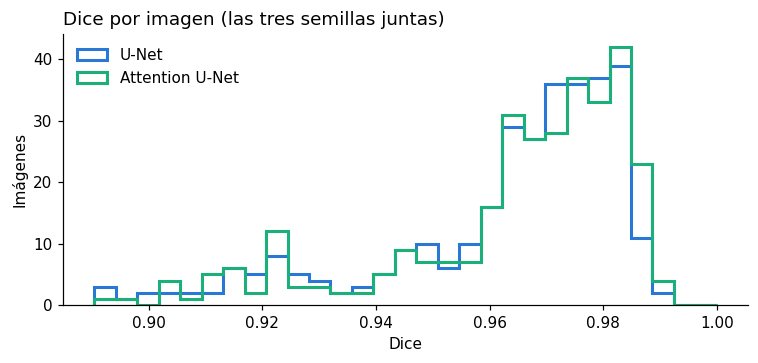

Peores casos:


,arch,image_id,source,tb,seed,dice,iou
48,attention_unet,CHNCXR_0423_1,shenzhen,1,42,0.890,0.803
627,unet,MCUCXR_0150_1,montgomery,1,44,0.891,0.804
472,unet,CHNCXR_0423_1,shenzhen,1,43,0.893,0.807
578,unet,CHNCXR_0423_1,shenzhen,1,44,0.894,0.808
366,unet,CHNCXR_0423_1,shenzhen,1,42,0.896,0.811
260,attention_unet,CHNCXR_0423_1,shenzhen,1,44,0.896,0.811
382,unet,CHNCXR_0527_1,shenzhen,1,42,0.902,0.821
594,unet,CHNCXR_0527_1,shenzhen,1,44,0.902,0.821
276,attention_unet,CHNCXR_0527_1,shenzhen,1,44,0.903,0.823
97,attention_unet,MCUCXR_0150_1,montgomery,1,42,0.903,0.823


In [6]:
per_image = pd.read_csv(SEG_RESULTS_DIR / "test_per_image.csv").merge(
    split[["image_id", "source", "tb"]], on="image_id")

display(per_image.groupby(["arch", "source"])["dice"].describe()[["count", "mean", "std", "min"]].round(3))

fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.linspace(per_image["dice"].min(), 1, 30)
for arch in [a for a in ARCH_NAMES if a in set(per_image["arch"])]:
    group = per_image[per_image["arch"] == arch]
    ax.hist(group["dice"], bins=bins, histtype="step", lw=2, color=ARCH_COLORS[arch], label=ARCH_NAMES[arch])
ax.set_title("Dice por imagen (las tres semillas juntas)", loc="left")
ax.set_xlabel("Dice"); ax.set_ylabel("Imágenes"); ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

print("Peores casos:")
display(per_image.sort_values("dice").head(10)[["arch", "image_id", "source", "tb", "seed", "dice", "iou"]].round(3))

Los casos difíciles son los informativos. **Los mismos identificadores aparecen con las tres semillas**, así que no son fallos aleatorios del entrenamiento: son radiografías difíciles o con máscaras manuales discutibles.

### 6.1 Comparación entre arquitecturas

El objetivo no es elegir el mejor segmentador, sino saber **si las máscaras de cada técnica son realmente distintas**, porque eso es lo que podría cambiar las características radiómicas en la etapa siguiente.

La comparación es sencilla: se toma la diferencia entre el Dice medio de ambas redes y se compara con la **variación entre semillas** (cuánto cambia el resultado solo por repetir el entrenamiento). Si la diferencia es mayor, se debe a la arquitectura y no al azar. Como complemento se cuenta en cuántas imágenes de prueba gana cada red.

In [7]:
if not {"unet", "attention_unet"} <= set(per_image["arch"]):
    print("Falta entrenar Attention U-Net: la comparación se completa al tener las dos arquitecturas.")
else:
    dice = metrics.groupby("arch")["test_dice"].agg(["mean", "std"])
    by_image = per_image.pivot_table(index="image_id", columns="arch", values="dice", aggfunc="mean")
    diff = dice.loc["attention_unet", "mean"] - dice.loc["unet", "mean"]
    display(pd.Series({
        "Dice medio U-Net": f"{dice.loc['unet', 'mean']:.4f}",
        "Dice medio Attention U-Net": f"{dice.loc['attention_unet', 'mean']:.4f}",
        "Diferencia (Attention − U-Net)": f"{diff:+.4f}",
        "Variación entre semillas (desviación)": f"{dice['std'].max():.4f}",
        "Imágenes donde gana Attention U-Net": f"{(by_image['attention_unet'] > by_image['unet']).sum()} de {len(by_image)}",
    }).to_frame("valor"))

,valor
Dice medio U-Net,0.9631
Dice medio Attention U-Net,0.9646
Diferencia (Attention − U-Net),+0.0015
Variación entre semillas (desviación),0.0005
Imágenes donde gana Attention U-Net,69 de 106


**Conclusiones de la comparación**

- **Las máscaras difieren poco, pero existe variación**: Attention U-Net tiene un Dice medio 0,0015 mayor, tres veces la variación entre semillas (0,0005), y gana en 69 de las 106 imágenes.
- **Las imágenes difíciles son las mismas para ambas** (`CHNCXR_0423_1`, `CHNCXR_0527_1`, `MCUCXR_0150_1`, todas TB). Ahí las dos técnicas fallan de forma parecida.
- **Costo y estabilidad**: Attention U-Net tiene el triple de parámetros, tarda unas cinco veces más por época y su validación es más inestable al inicio (sección 5), coherente con su normalización por lote.

**Para el proyecto:** ambas técnicas producen máscaras muy parecidas. La pregunta de la siguiente etapa es si una diferencia de este tamaño alcanza a cambiar las características radiómicas y los clasificadores, o si estas se mantienen estables entre técnicas.

## 7. Siguientes pasos (pendientes)

Esta etapa cierra con U-Net y Attention U-Net entrenadas y evaluadas. Lo que sigue, en orden:

In [ ]:
# 1: generar las máscaras de las 704 imágenes de Montgomery-Shenzhen para la radiómica (predict.py)
# 2: integrar MedSAM al registro de métodos
# 3: Considerar otra técnica de segmentación diferente a U-Net y Attention U-Net, idealmente no basada en deep learning (k-means, por ejemplo)